# Canopy rings: a tree-height joyplot in the shape of tree rings
**#30DayMapChallenge · Day 25 · Is this a map?**

Each ring is a real circle on the ground around a centre point. Canopy height is sampled along that circle and pushed outward as bumps, like a joyplot wrapped into a ring. Tall, uneven forest makes rough, crowded rings. Open ground (city, water, fields) makes smooth ones. North is up, and every point keeps its true distance and bearing from the centre, so it's still a map.

**Data:** [High Resolution Canopy Height Maps by WRI and Meta](https://registry.opendata.aws/dataforgood-fb-forests/) (CC BY 4.0), about 1 m resolution, global. The data is streamed from a public S3 bucket and needs no AWS account. Only the window around each city is read, at a coarser resolution, so each city downloads a few MB rather than whole tiles.

Run the cells top to bottom. Each city's data is cached in `cache/`, so re-styling doesn't download anything again.

In [2]:
# Run once if needed
# %pip install rasterio mercantile numpy scipy matplotlib

In [3]:
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from scipy.ndimage import gaussian_filter1d

import mercantile
import rasterio
from rasterio.enums import Resampling
from rasterio.transform import from_bounds
from rasterio.windows import from_bounds as window_from_bounds

CACHE = Path("cache"); CACHE.mkdir(exist_ok=True)
OUT = Path("output"); OUT.mkdir(exist_ok=True)

# Meta/WRI global canopy height, v1. Tiles are named by zoom-9 quadkey, in EPSG:3857.
CHM_URL = "/vsicurl/https://dataforgood-fb-data.s3.amazonaws.com/forests/v1/alsgedi_global_v6_float/chm/{qk}.tif"

GDAL_ENV = dict(
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR",   # don't list the bucket
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif",
    GDAL_HTTP_MULTIRANGE="YES",
    GDAL_HTTP_MERGE_CONSECUTIVE_RANGES="YES",
)

## Cities
Each city is centred on a landmark with a big urban forest within reach. `radius_km` sets how far the outermost ring reaches. Add, remove or move cities freely.

In [27]:
CITIES = {
    "Rio de Janeiro": dict(lon=-43.2105, lat=-22.9519, radius_km=6,
                           centre="Christ the Redeemer, Tijuca Forest"),
    "Vancouver":      dict(lon=-123.1443, lat=49.3017, radius_km=5,
                           centre="Stanley Park"),
    "Oslo":           dict(lon=10.7336, lat=59.9116, radius_km=9,
                           centre="City Hall, reaching into Nordmarka"),
    "Hong Kong":      dict(lon=114.1455, lat=22.2759, radius_km=6,
                           centre="Victoria Peak"),
    "Vienna":         dict(lon=16.3725, lat=48.2085, radius_km=10,
                           centre="St. Stephen's Cathedral, reaching the Vienna Woods"),
    "Sydney":         dict(lon=151.2108, lat=-33.8523, radius_km=10,
                           centre="Harbour Bridge, reaching Lane Cove"),
}

# Angular smoothing per city: 1.5 = crisp, 3-4 = wood grain, 8+ = blurry.
# Cities not listed use DEFAULT_SMOOTH.
DEFAULT_SMOOTH = 1.5
SMOOTH = {
    "Rio de Janeiro": 4,
    "Oslo": 3,
    "Sydney": 3,
}

## Fetch canopy height around a point
Builds a square grid about 10 m per pixel in Web Mercator around the centre. For each zoom-9 tile that touches it, the code reads only the overlapping window and lets GDAL downsample it (averaging, using the file's overviews). The result is cached as `.npy`.

In [7]:
def fetch_canopy(name, lon, lat, radius_km, res_m=10, pad=1.15, url=CHM_URL, **_):
    """Return (grid, half_extent_ground_m). The grid is square, north-up, in metres of height."""
    cache = CACHE / f"{name.lower().replace(' ', '_')}_{radius_km}km_{res_m}m.npy"
    half_ground = radius_km * 1000 * pad
    if cache.exists():
        return np.load(cache), half_ground

    k = 1 / np.cos(np.radians(lat))            # Mercator metres per ground metre
    cx, cy = mercantile.xy(lon, lat)
    half = half_ground * k
    bounds = (cx - half, cy - half, cx + half, cy + half)
    n = int(round(2 * half_ground / res_m))
    dst_t = from_bounds(*bounds, n, n)
    grid = np.zeros((n, n), np.float32)

    sw = mercantile.lnglat(bounds[0], bounds[1])
    ne = mercantile.lnglat(bounds[2], bounds[3])
    tiles = list(mercantile.tiles(sw.lng, sw.lat, ne.lng, ne.lat, zooms=9))

    with rasterio.Env(**GDAL_ENV):
        for t in tiles:
            qk = mercantile.quadkey(t)
            try:
                src = rasterio.open(url.format(qk=qk))
            except rasterio.errors.RasterioIOError as e:
                print(f"  {name}: tile {qk} not available ({e.__class__.__name__}), skipped")
                continue
            with src:
                assert src.crs.to_epsg() == 3857, f"unexpected CRS {src.crs}"
                l = max(bounds[0], src.bounds.left);  r = min(bounds[2], src.bounds.right)
                b = max(bounds[1], src.bounds.bottom); tp = min(bounds[3], src.bounds.top)
                if l >= r or b >= tp:
                    continue
                # where this piece lands in our grid
                dwin = window_from_bounds(l, b, r, tp, dst_t).round_offsets().round_lengths()
                h, w = int(dwin.height), int(dwin.width)
                if h == 0 or w == 0:
                    continue
                swin = window_from_bounds(l, b, r, tp, src.transform)
                arr = src.read(1, window=swin, out_shape=(h, w),
                               resampling=Resampling.average).astype(np.float32)
                if src.nodata is not None:
                    arr[arr == src.nodata] = 0
                r0, c0 = int(dwin.row_off), int(dwin.col_off)
                tgt = grid[r0:r0 + h, c0:c0 + w]
                np.maximum(tgt, arr[:tgt.shape[0], :tgt.shape[1]], out=tgt)
            print(f"  {name}: read tile {qk}")

    grid[~np.isfinite(grid)] = 0
    grid = np.clip(grid, 0, 100)               # anything taller is an artefact
    np.save(cache, grid)
    return grid, half_ground

In [8]:
data = {}
for name, cfg in CITIES.items():
    print(name)
    data[name] = fetch_canopy(name, **cfg)
    g = data[name][0]
    print(f"  grid {g.shape}, mean {g.mean():.1f} m, 99th pct {np.percentile(g, 99):.1f} m")

Rio de Janeiro
  grid (1380, 1380), mean 3.5 m, 99th pct 21.0 m
Vancouver
  grid (1150, 1150), mean 2.4 m, 99th pct 28.0 m
Oslo
  grid (2070, 2070), mean 4.5 m, 99th pct 21.0 m
Hong Kong
  grid (1380, 1380), mean 1.1 m, 99th pct 14.0 m
Vienna
  grid (2300, 2300), mean 3.8 m, 99th pct 25.0 m
Sydney
  grid (2300, 2300), mean 1.4 m, 99th pct 18.0 m


Quick check: plain canopy-height rasters, so you can see what each ring plot is drawn from.

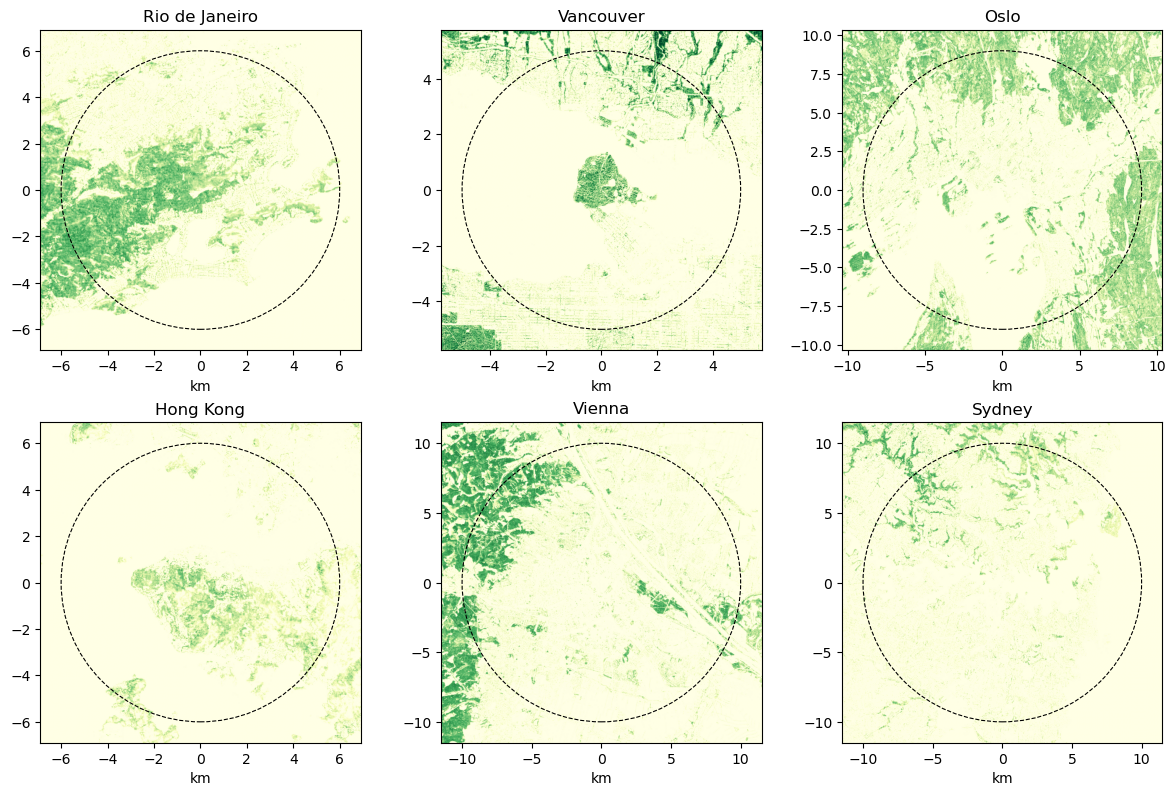

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (name, (g, half)) in zip(axes.flat, data.items()):
    ax.imshow(g, cmap="YlGn", vmin=0, vmax=35, extent=[-half/1000, half/1000, -half/1000, half/1000])
    r = CITIES[name]["radius_km"]
    ax.add_patch(plt.Circle((0, 0), r, fill=False, ls="--", lw=0.8))
    ax.set_title(name); ax.set_xlabel("km")
plt.tight_layout()

## Draw the rings
Rings are drawn **outermost first** and each one is filled with the background colour. That way inner rings sit in front and hide the bumps behind them, the same overlap trick a joyplot uses.

Settings worth tweaking:
- `rings`: fewer rings look bolder, more look finer-grained like real wood
- `gain`: how far the tallest canopy pushes out, in ring spacings
- `smooth`: angular smoothing (in samples), set per city in the `SMOOTH` dictionary in the Cities cell. Passing `smooth=` to `poster()` or `grid_poster()` overrides it for every city.
- `palette`: `"wood"`, `"ink"` (dark background) or `"paper"`

In [29]:
PALETTES = {
    "wood":  dict(bg="#f3e6cf", ink="#5a3a22"),
    "paper": dict(bg="#fbfaf6", ink="#1d1d1b"),
    "ink":   dict(bg="#14120f", ink="#e9dcc3"),
}

def ring_profiles(grid, half_ground, radius_m, rings, pts=1440, smooth=1.5):
    n = grid.shape[0]
    theta = np.linspace(0, 2 * np.pi, pts, endpoint=False)   # 0 = east, counter-clockwise
    radii = np.linspace(radius_m / rings, radius_m, rings)
    profiles = []
    for r in radii:
        dx, dy = r * np.cos(theta), r * np.sin(theta)
        col = np.clip(((dx + half_ground) / (2 * half_ground) * n).astype(int), 0, n - 1)
        row = np.clip(((half_ground - dy) / (2 * half_ground) * n).astype(int), 0, n - 1)
        profiles.append(gaussian_filter1d(grid[row, col], smooth, mode="wrap"))
    return theta, radii, np.array(profiles)


def draw_rings(ax, grid, half_ground, radius_km, rings=45, gain=4, smooth=1.5,
               palette="wood", hmax=None, pith=True):
    bg, ink = PALETTES[palette]["bg"], PALETTES[palette]["ink"]
    radius_m = radius_km * 1000
    theta, radii, H = ring_profiles(grid, half_ground, radius_m, rings, smooth=smooth)
    spacing = radii[1] - radii[0]
    hmax = hmax or max(np.percentile(H, 99.5), 1)
    scale = gain * spacing / hmax

    ax.set_facecolor(bg); ax.set_aspect("equal"); ax.axis("off")
    for k in range(rings - 1, -1, -1):
        rr = radii[k] + H[k] * scale
        xy = np.column_stack([rr * np.cos(theta), rr * np.sin(theta)])
        ax.add_patch(Polygon(xy, closed=True, facecolor=bg, edgecolor=ink,
                             linewidth=0.45 + 0.9 * k / rings, joinstyle="round"))
    if pith:
        ax.plot(0, 0, "o", color=ink, ms=2.5)
    lim = radius_m + (gain + 0.5) * spacing
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    return spacing, hmax


def poster(name, palette="wood", rings=45, gain=4, smooth=None, save=True):
    cfg = CITIES[name]
    grid, half = data[name]
    if smooth is None:
        smooth = SMOOTH.get(name, DEFAULT_SMOOTH)
    bg, ink = PALETTES[palette]["bg"], PALETTES[palette]["ink"]
    fig = plt.figure(figsize=(9, 11), facecolor=bg)
    ax = fig.add_axes([0.04, 0.08, 0.92, 0.78])
    spacing, hmax = draw_rings(ax, grid, half, cfg["radius_km"], rings, gain, smooth, palette)
    fig.text(0.5, 0.955, name, ha="center", va="top", color=ink, fontsize=26, family="serif")
    fig.text(0.5, 0.905, f"Canopy height in rings around {cfg['centre']}",
             ha="center", va="top", color=ink, fontsize=11, family="serif", alpha=0.8)
    fig.text(0.5, 0.045,
             f"{rings} rings, one every {spacing:,.0f} m, out to {cfg['radius_km']} km · north is up · "
             f"tallest bumps ≈ {hmax:.0f} m canopy",
             ha="center", color=ink, fontsize=8.5, family="serif", alpha=0.75)
    fig.text(0.5, 0.022, "Data: High Resolution Canopy Height Maps by WRI and Meta (CC BY 4.0)",
             ha="center", color=ink, fontsize=7, family="serif", alpha=0.55)
    if save:
        path = OUT / f"canopy_rings_{name.lower().replace(' ', '_')}_{palette}.png"
        fig.savefig(path, dpi=250, facecolor=bg)
        print("saved", path)
    return fig

## One poster per city

saved output\canopy_rings_rio_de_janeiro_wood.png


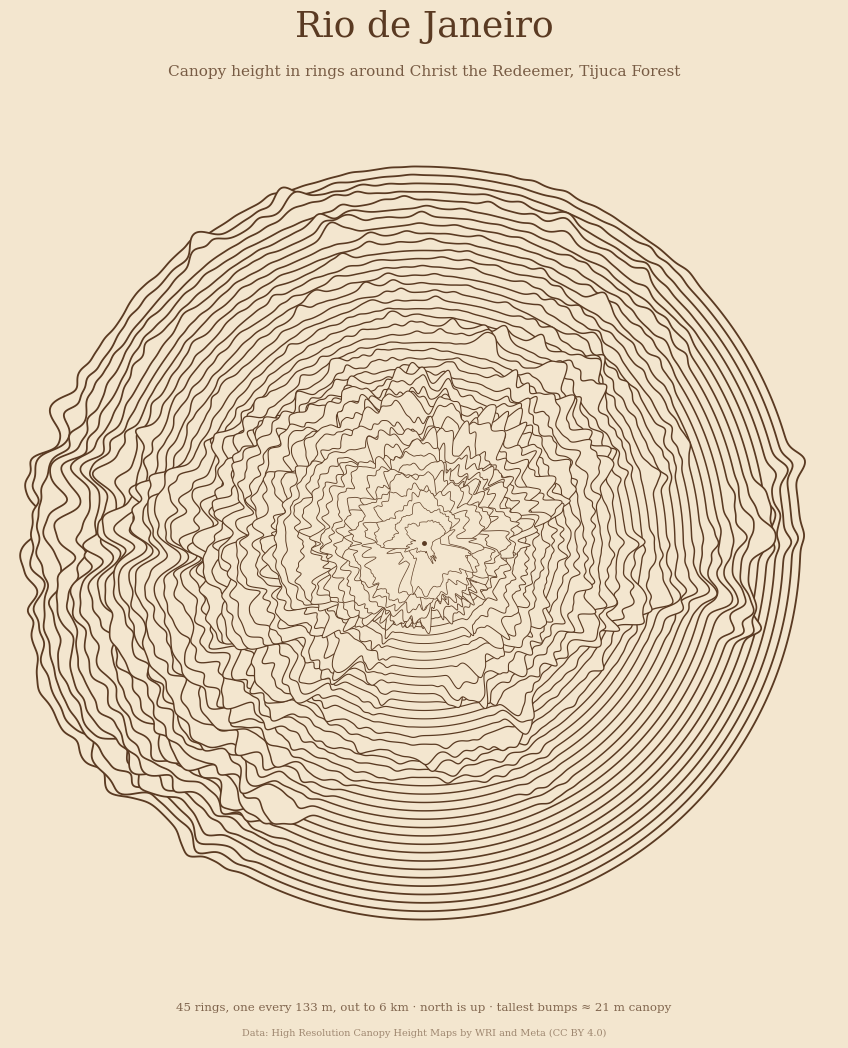

saved output\canopy_rings_vancouver_wood.png


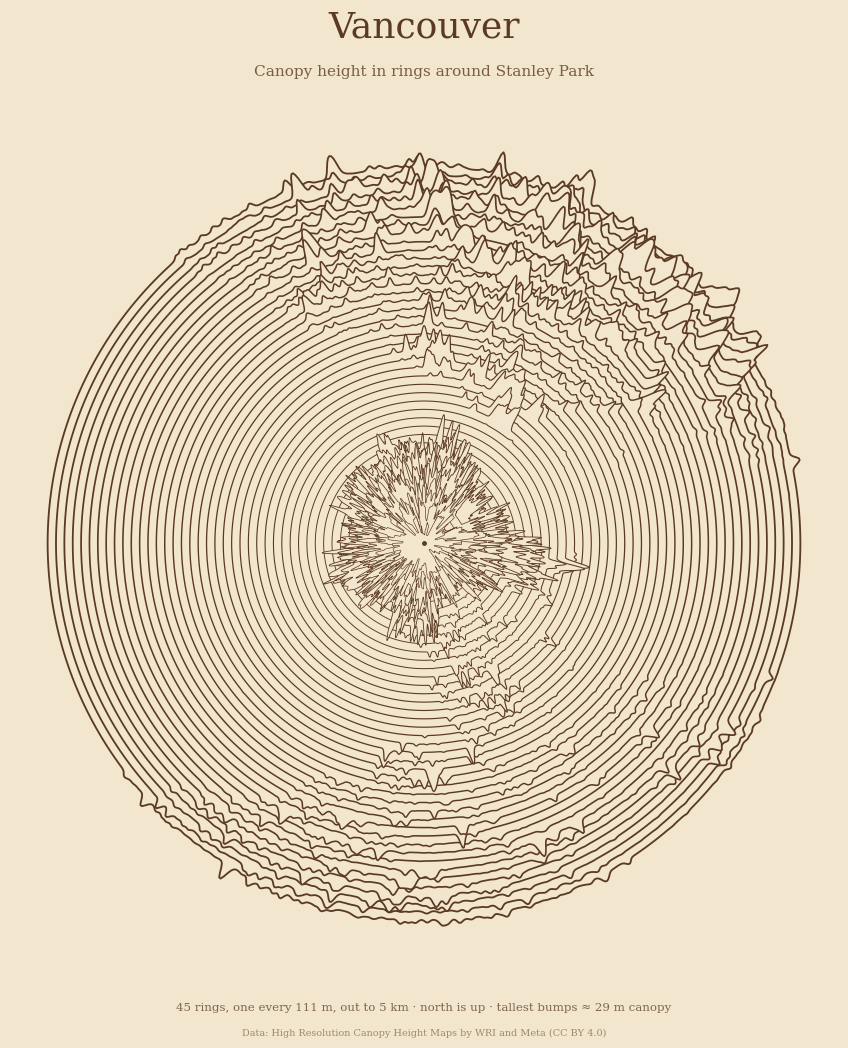

saved output\canopy_rings_oslo_wood.png


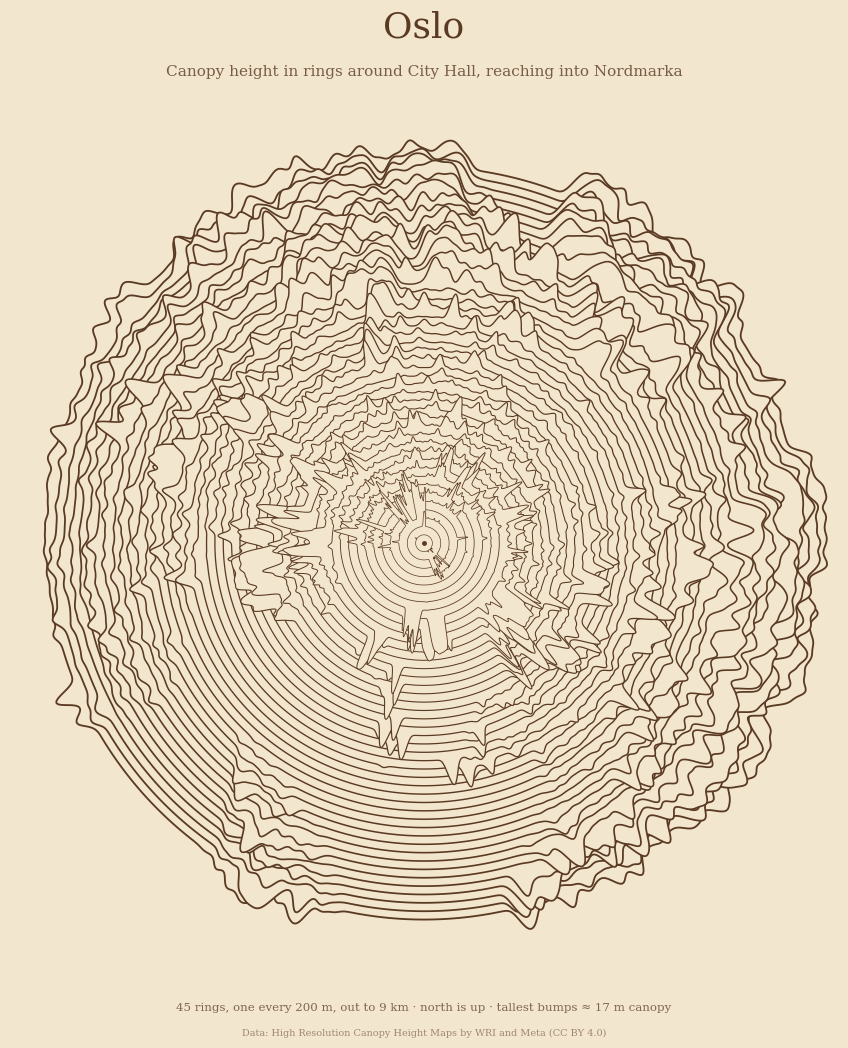

saved output\canopy_rings_hong_kong_wood.png


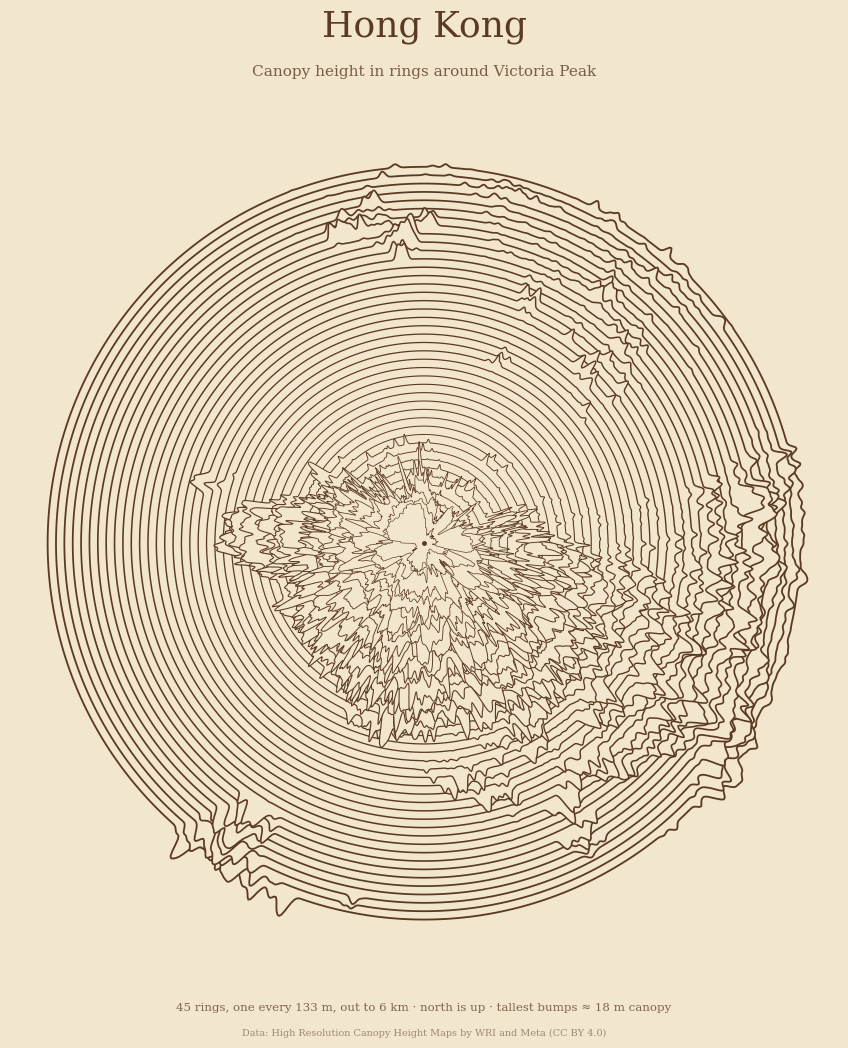

saved output\canopy_rings_vienna_wood.png


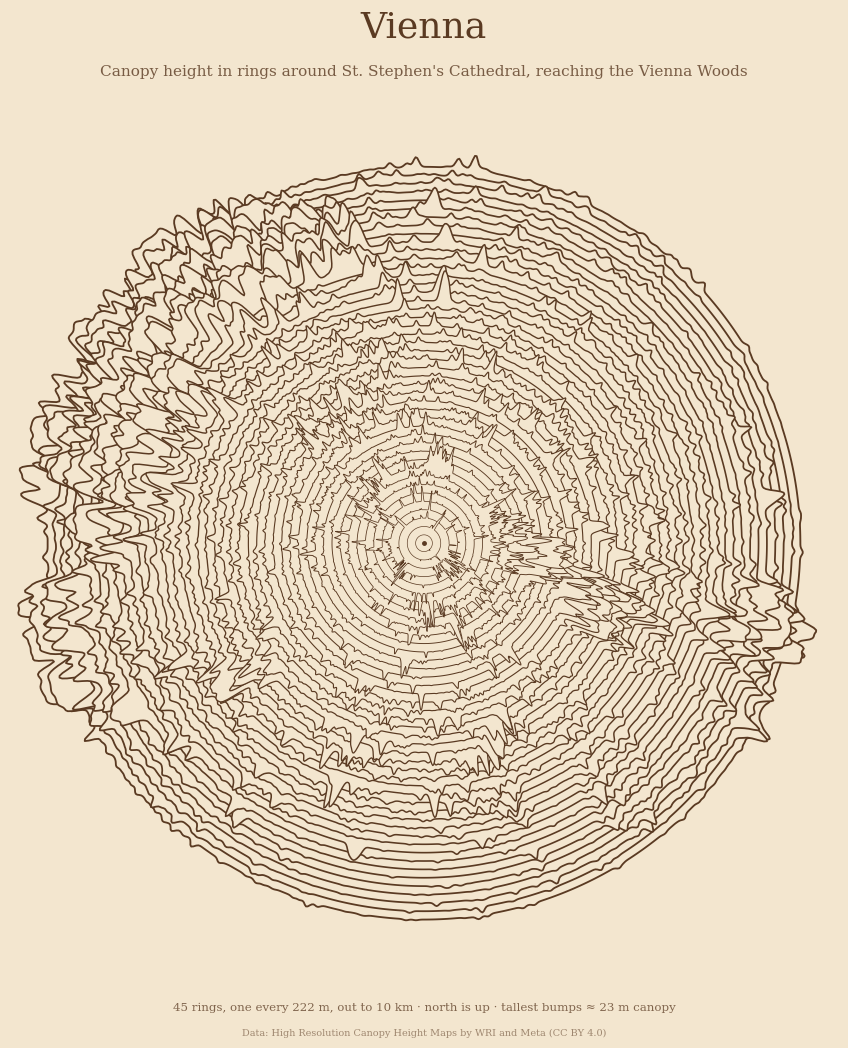

saved output\canopy_rings_sydney_wood.png


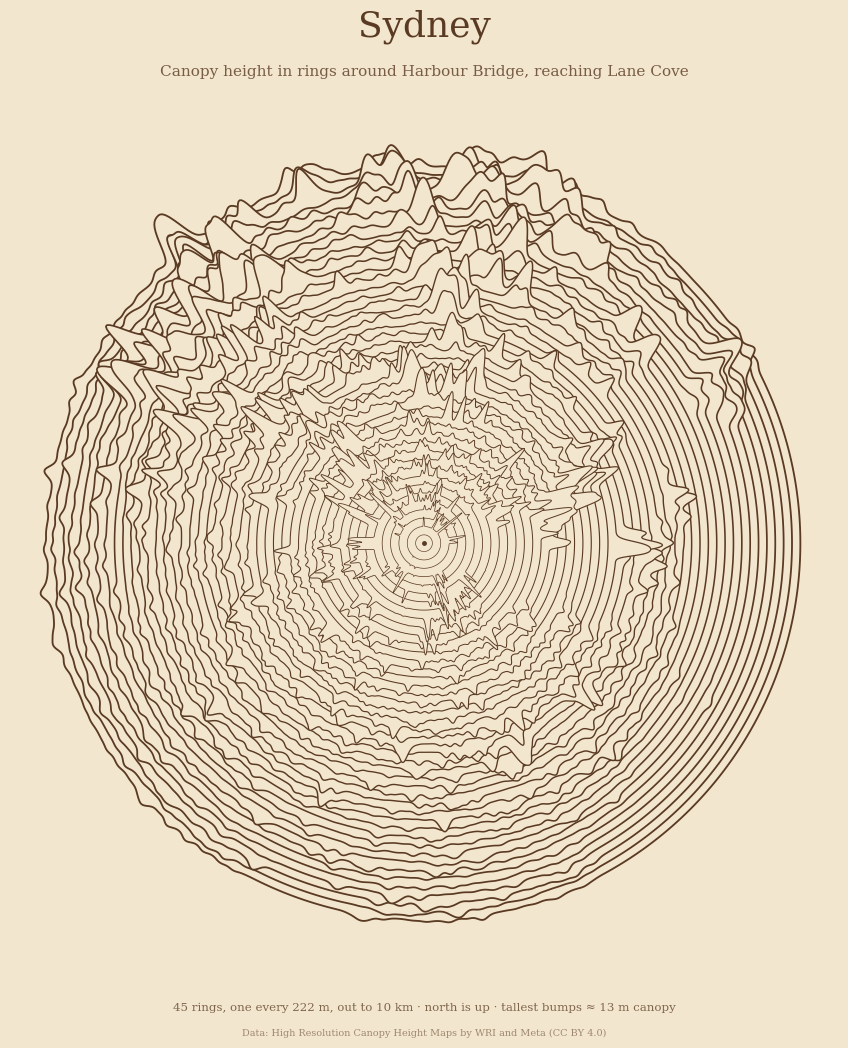

In [33]:
for name in CITIES:
    poster(name, palette="wood")
    plt.show()

## All cities side by side
Every panel uses the same height scale (`hmax` is shared), so bump sizes can be compared between cities. Ring spacing still differs because each city has its own radius.

saved output\canopy_rings_all_wood.png


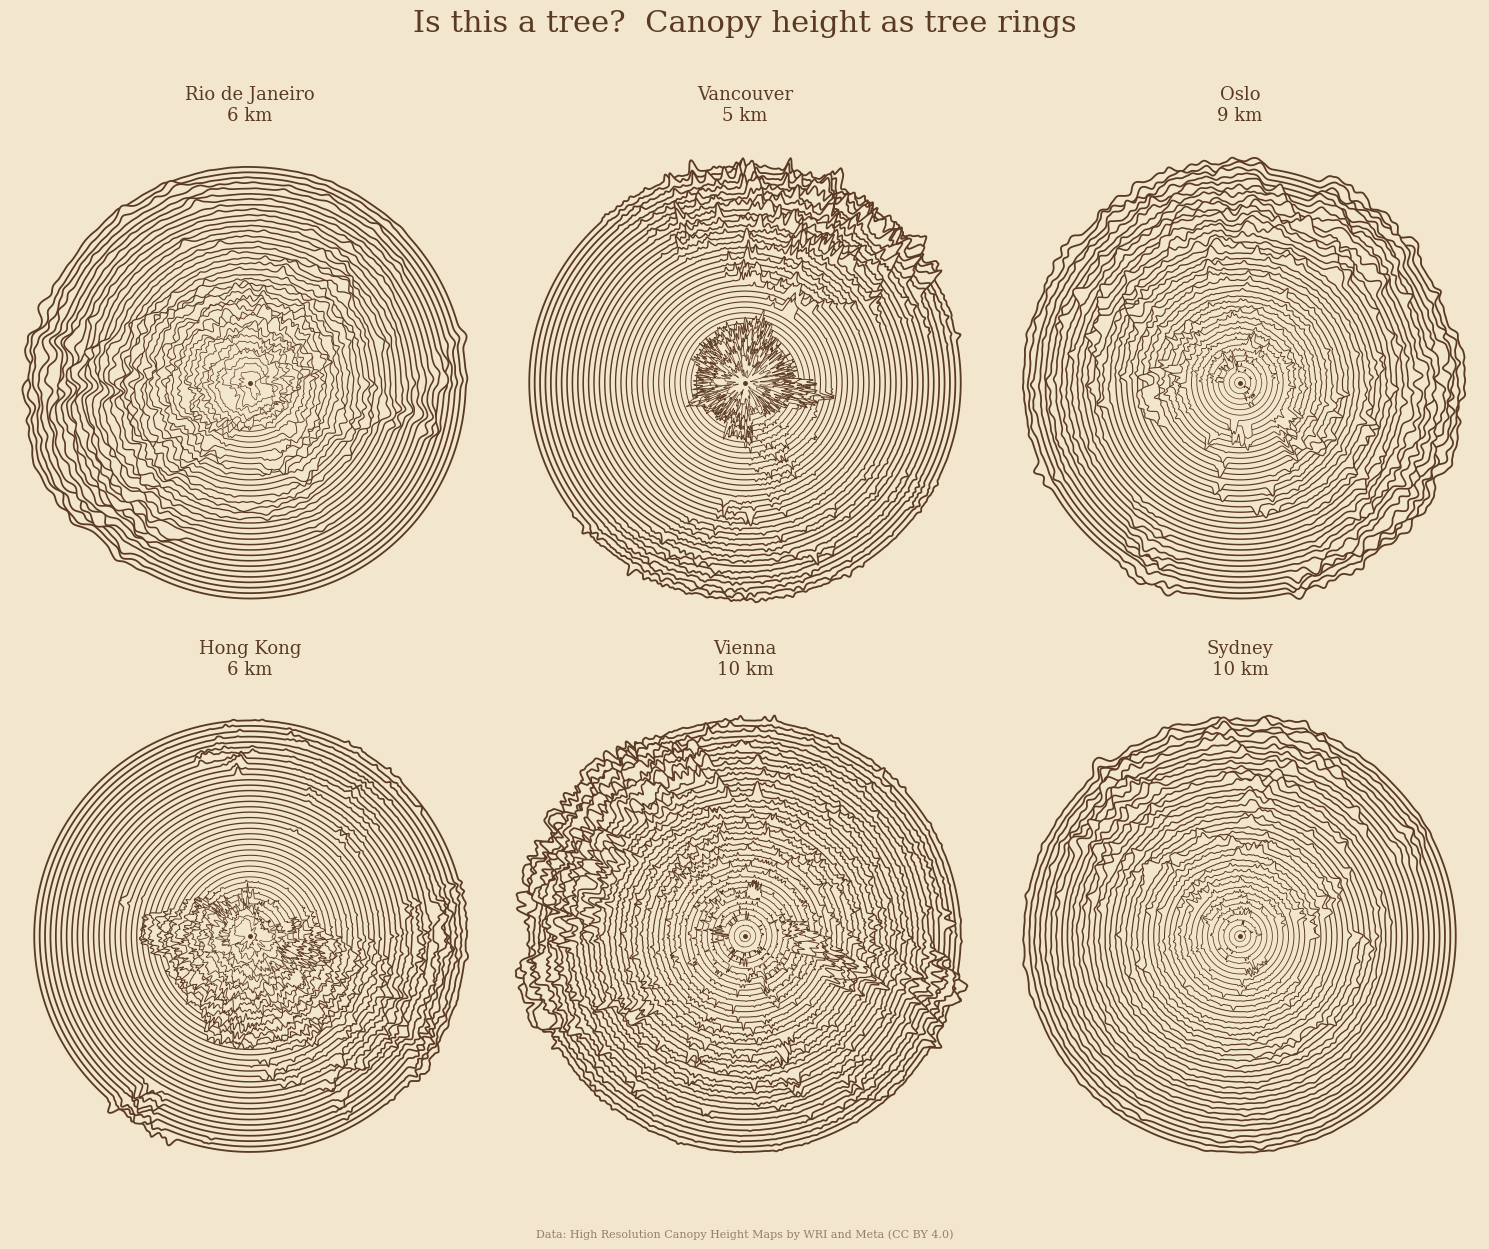

In [16]:
def grid_poster(palette="wood", rings=40, gain=4, cols=3, smooth=None):
    bg, ink = PALETTES[palette]["bg"], PALETTES[palette]["ink"]
    shared_hmax = max(np.percentile(g, 99.5) for g, _ in data.values())
    rows = int(np.ceil(len(data) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 6.2 * rows), facecolor=bg)
    for ax, (name, (g, half)) in zip(np.ravel(axes), data.items()):
        sm = smooth if smooth is not None else SMOOTH.get(name, DEFAULT_SMOOTH)
        draw_rings(ax, g, half, CITIES[name]["radius_km"], rings, gain,
                   smooth=sm, palette=palette, hmax=shared_hmax)
        ax.set_title(f"{name}\n{CITIES[name]['radius_km']} km", color=ink,
                     family="serif", fontsize=13, pad=16)
    for ax in np.ravel(axes)[len(data):]:
        ax.axis("off")
    fig.suptitle("Is this a tree?  Canopy height as tree rings", color=ink,
                 family="serif", fontsize=22, y=0.995)
    fig.text(0.5, 0.005, "Data: High Resolution Canopy Height Maps by WRI and Meta (CC BY 4.0)",
             ha="center", color=ink, family="serif", fontsize=8, alpha=0.6)
    plt.tight_layout(rect=(0, 0.015, 1, 0.97), h_pad=3)
    path = OUT / f"canopy_rings_all_{palette}.png"
    fig.savefig(path, dpi=200, facecolor=bg)
    print("saved", path)
    return fig

grid_poster("wood"); plt.show()

## Variations to try
- `poster("Hong Kong", palette="ink")` gives cream rings on a near-black background.
- Lower `gain` (3–4) keeps the rings readable. Higher `gain` (8+) makes them tangle like burl wood.
- Fewer rings (`rings=25`) look bold and graphic. More (`rings=80`, `smooth=1`) look like fine-grained wood.
- Move a centre onto a single famous tree or the highest point of a park, so the pith marks something meaningful.